In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

In [2]:
def standardize_spectrum(X):
    mean = np.nanmean(X, axis=1, keepdims=True)
    std = np.nanstd(X, axis=1, keepdims=True)

    std[std == 0] = 1.0

    X_std = (X - mean) / std
    X_std[~np.isfinite(X_std)] = 0.0

    return X_std.astype(np.float32)

In [3]:
def CNN(input_dim, dropout_rate=0.2):
    model = tf.keras.Sequential([
        layers.Input(shape=(input_dim, 1)),

        layers.Conv1D(32, kernel_size=9, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, kernel_size=7, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
        layers.BatchNormalization(),

        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout_rate),

        layers.Dense(4, activation="softmax")])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
        loss="mse",
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(name="mae"),
            tf.keras.metrics.CategoricalAccuracy(name="dominant_acc")])

    return model

In [4]:
def count_dominant_classes(y_split, split_name, class_names):
    dominant_indices = np.argmax(y_split, axis=1)
    counts = pd.Series(dominant_indices).value_counts().sort_index()
    result = pd.DataFrame({"class": class_names, "count": [counts.get(i, 0) for i in range(len(class_names))]})

    result["percentage"] = 100 * result["count"] / len(y_split)

    print(f"\n{split_name}:")
    print(result.to_string(index=False))

In [5]:
class_names = ["HII", "PN", "SNR", "DIG"]

data_dir = Path("../Mock Spectra")

X = np.load(data_dir / "mock_spectra_combined_OI.npy")
y = np.load(data_dir / "mock_spectra_combined_weights_OI.npy")
metadata = pd.read_csv(data_dir / "mock_spectra_combined_metadata_OI.csv")

X = X.astype(np.float32)
y = y.astype(np.float32)

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (10000, 3841)
Y shape: (10000, 4)


In [6]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [7]:
X = standardize_spectrum(X)

#dominant_class = np.argmax(y, axis=1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    #stratify=dominant_class
    )

#temp_dominant_class = np.argmax(y_temp, axis=1)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    #stratify=temp_dominant_class
    )

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

count_dominant_classes(y_train, "Training set", class_names)
count_dominant_classes(y_val, "Validation set", class_names)
count_dominant_classes(y_test, "Test set", class_names)

Train: (7000, 3841, 1) (7000, 4)
Val:   (1500, 3841, 1) (1500, 4)
Test:  (1500, 3841, 1) (1500, 4)

Training set:
class  count  percentage
  HII   1756   25.085714
   PN   1734   24.771429
  SNR   1734   24.771429
  DIG   1776   25.371429

Validation set:
class  count  percentage
  HII    377   25.133333
   PN    364   24.266667
  SNR    358   23.866667
  DIG    401   26.733333

Test set:
class  count  percentage
  HII    359   23.933333
   PN    384   25.600000
  SNR    395   26.333333
  DIG    362   24.133333


In [8]:
model = CNN(X.shape[1], dropout_rate=0.3)
model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_mae",
    patience=25,
    restore_best_weights=True,
    mode="min")

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_mae",
    factor=0.5,
    patience=8,
    min_lr=1e-6,
    mode="min")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=128,
    callbacks=[early_stop, reduce_lr])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3841, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3841, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1920, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1920, 64)       │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1920, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 960, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 960, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 960, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,220 (254.77 KB)

 Trainable params: 64,772 (253.02 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 14s 231ms/step - dominant_acc: 0.3517 - loss: 0.0655 - mae: 0.1947 - val_dominant_acc: 0.2387 - val_loss: 0.0719 - val_mae: 0.2051 - learning_rate: 3.0000e-04
Epoch 2/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 233ms/step - dominant_acc: 0.4203 - loss: 0.0589 - mae: 0.1832 - val_dominant_acc: 0.2387 - val_loss: 0.0943 - val_mae: 0.2348 - learning_rate: 3.0000e-04
Epoch 3/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 237ms/step - dominant_acc: 0.4629 - loss: 0.0552 - mae: 0.1755 - val_dominant_acc: 0.2387 - val_loss: 0.1363 - val_mae: 0.2778 - learning_rate: 3.0000e-04
Epoch 4/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 240ms/step - dominant_acc: 0.4807 - loss: 0.0530 - mae: 0.1706 - val_dominant_acc: 0.2387 - val_loss: 0.1549 - val_mae: 0.2955 - learning_rate: 3.0000e-04
Epoch 5/100
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 243ms/step - dominant_acc: 0.4894 - loss: 0.0518 - mae: 0.1685 - val_dominant_acc: 0.2387 - val_loss: 0.1532 - val_mae: 0.2946 - learning_rate: 3.0000e-04
Epoch 6/10

In [9]:
test_results = model.evaluate(X_test, y_test, return_dict=True)
print("Test metrics:")
for name, value in test_results.items():
    print(f"  {name}: {value:.4f}")

y_pred = model.predict(X_test)

y_true_class = np.argmax(y_test, axis=1)
y_pred_class = np.argmax(y_pred, axis=1)

print(classification_report(
    y_true_class,
    y_pred_class,
    target_names=class_names,
    digits=3))

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - dominant_acc: 0.6307 - loss: 0.0315 - mae: 0.1227
Test metrics:
  dominant_acc: 0.6307
  loss: 0.0315
  mae: 0.1227
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
              precision    recall  f1-score   support

         HII      0.499     0.554     0.525       359
          PN      0.643     0.638     0.641       384
         SNR      0.729     0.830     0.776       395
         DIG      0.644     0.481     0.551       362

    accuracy                          0.631      1500
   macro avg      0.629     0.626     0.623      1500
weighted avg      0.631     0.631     0.627      1500



In [10]:
absolute_errors = np.abs(y_test - y_pred)
median_absolute_error = np.median(absolute_errors, axis=0)
mean_absolute_error = np.mean(absolute_errors, axis=0)

weight_error_table = pd.DataFrame({
    "class": class_names,
    "median_absolute_error": median_absolute_error,
    "mean_absolute_error": mean_absolute_error,
    "median_error_percent": 100 * median_absolute_error})

print("Overall median absolute error:", np.median(absolute_errors))
weight_error_table

Overall median absolute error: 0.08231488


,class,median_absolute_error,mean_absolute_error,median_error_percent
0,HII,0.118275,0.159378,11.827540
1,PN,0.080158,0.121518,8.015791
2,SNR,0.056623,0.083159,5.662318
3,DIG,0.085426,0.126870,8.542645


In [11]:
prevalent_mask = np.max(y_test, axis=1) > 0.5

print("Spectra with a weight > 0.5:", prevalent_mask.sum())
print(classification_report(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    target_names=class_names,
    digits=3))

Spectra with a weight > 0.5: 871
              precision    recall  f1-score   support

         HII      0.616     0.681     0.647       207
          PN      0.733     0.808     0.769       214
         SNR      0.875     0.937     0.905       239
         DIG      0.867     0.616     0.720       211

    accuracy                          0.767       871
   macro avg      0.773     0.761     0.760       871
weighted avg      0.776     0.767     0.765       871



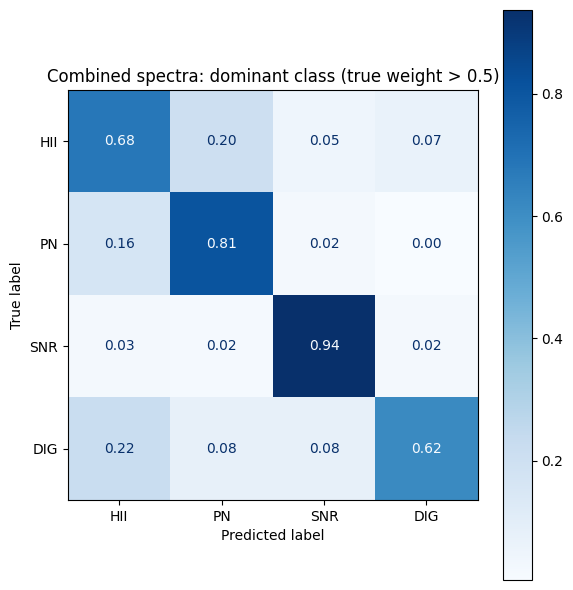

In [12]:
cm = confusion_matrix(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    normalize="true")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format=".2f", cmap="Blues")
plt.title("Combined spectra: dominant class (true weight > 0.5)")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train loss")
axes[0].plot(history.history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical cross-entropy")
axes[0].legend()

axes[1].plot(history.history["mae"], label="train MAE")
axes[1].plot(history.history["val_mae"], label="val MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean absolute weight error")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(y_test), size=4, replace=False)
x_positions = np.arange(len(class_names))
bar_width = 0.38

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)

for ax, index in zip(axes.flat, example_indices):
    ax.bar(
        x_positions - bar_width / 2,
        y_test[index],
        width=bar_width,
        label="True")
    ax.bar(
        x_positions + bar_width / 2,
        y_pred[index],
        width=bar_width,
        label="Predicted")
    ax.set_xticks(x_positions, class_names)
    ax.set_ylim(0, 1)
    ax.set_title(f"Test spectrum {index}")

axes[0, 0].legend()
fig.supylabel("Mixture weight")
plt.tight_layout()
plt.show()

In [ ]:
model.save("cnn_combined_spectra_OI.keras")